# Project 4A: Image Warping and Mosaicing

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

ROOT = Path.cwd()
if (ROOT / "proj4" / "parta").is_dir():
    ROOT = ROOT / "proj4" / "parta"
elif (ROOT / "parta").is_dir():
    ROOT = ROOT / "parta"
ASSETS = ROOT / "assets"
OUTPUTS = ROOT.parent / "assets"
OUTPUTS.mkdir(exist_ok=True)


def load_image(path):
    with Image.open(path) as image:
        return np.asarray(ImageOps.exif_transpose(image).convert("RGB"), dtype=np.float32) / 255


def show_images(images, titles, points=None, save_as=None):
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4))
    for i, ax in enumerate(np.atleast_1d(axes)):
        ax.imshow(images[i], vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(titles[i])
        ax.axis("off")
        if points is not None:
            for j, (x, y) in enumerate(points[i]):
                ax.plot(x, y, "r+", markersize=8)
                ax.text(x + 4, y + 4, str(j), color="yellow")
    fig.tight_layout()
    if save_as:
        fig.savefig(OUTPUTS / save_as, dpi=140, bbox_inches="tight")
    plt.show()


## A.2: Recover Homographies

In [2]:
def computeH(im1_pts, im2_pts):
    A, b = [], []
    for (x, y), (u, v) in zip(im1_pts, im2_pts):
        A.append([x, y, 1, 0, 0, 0, -u*x, -u*y])
        A.append([0, 0, 0, x, y, 1, -v*x, -v*y])
        b.extend([u, v])
    h = np.linalg.lstsq(A, b, rcond=None)[0]
    return np.append(h, 1).reshape(3, 3)


## A.3: Warping

In [ ]:
def canvas_bounds(images, homographies):
    corners = []
    for im, H in zip(images, homographies):
        height, width = im.shape[:2]
        p = np.array([[0, 0, 1], [width-1, 0, 1],
                      [width-1, height-1, 1], [0, height-1, 1]]).T
        q = H @ p
        corners.append((q[:2] / q[2]).T)
    corners = np.concatenate(corners)
    corners = np.round(corners, 8)
    xmin, ymin = np.floor(corners.min(axis=0)).astype(int)
    xmax, ymax = np.ceil(corners.max(axis=0)).astype(int)
    return xmin, ymin, xmax, ymax


def warp_image(im, H, method="bilinear", bounds=None):
    if bounds is None:
        bounds = canvas_bounds([im], [H])
    xmin, ymin, xmax, ymax = bounds
    xx, yy = np.meshgrid(np.arange(xmin, xmax+1), np.arange(ymin, ymax+1))
    coordinates = np.stack([xx.ravel(), yy.ravel(), np.ones(xx.size)])
    source = np.linalg.inv(H) @ coordinates
    with np.errstate(divide="ignore", invalid="ignore"):
        x, y = source[:2] / source[2]

    height, width = im.shape[:2]
    valid = ((x >= -1e-6) & (x <= width-1+1e-6)
             & (y >= -1e-6) & (y <= height-1+1e-6))
    x, y = np.clip(x[valid], 0, width-1), np.clip(y[valid], 0, height-1)
    if method == "nearest":
        values = im[np.floor(y + .5).astype(int), np.floor(x + .5).astype(int)]
    else:
        x0, y0 = np.floor(x).astype(int), np.floor(y).astype(int)
        x1, y1 = np.minimum(x0+1, width-1), np.minimum(y0+1, height-1)
        dx, dy = x-x0, y-y0
        if im.ndim == 3:
            dx, dy = dx[:, None], dy[:, None]
        values = ((1-dx)*(1-dy)*im[y0, x0] + dx*(1-dy)*im[y0, x1]
                  + (1-dx)*dy*im[y1, x0] + dx*dy*im[y1, x1])

    warped = np.zeros((xx.size,) + im.shape[2:], dtype=np.float32)
    warped[valid] = values
    return warped.reshape(xx.shape + im.shape[2:]), valid.reshape(xx.shape)


def warpImageNearestNeighbor(im, H, bounds=None):
    return warp_image(im, H, "nearest", bounds)[0]


def warpImageBilinear(im, H, bounds=None):
    return warp_image(im, H, "bilinear", bounds)[0]

### Rectification


In [4]:
RECTIFICATIONS = [{'name': 'Birthday poster',
  'slug': 'birthday',
  'image': 'rectification/left.jpg',
  'corners': [[231.43, 194.29], [391.43, 206.43], [395.0, 294.29], [239.29, 295.0]],
  'size': (800, 500)},
 {'name': 'Botanical print',
  'slug': 'botanical',
  'image': 'rectification/right.jpg',
  'corners': [[460.71, 185.0], [569.29, 181.43], [564.29, 326.43], [460.71, 323.57]],
  'size': (600, 800)}]


Birthday poster H =
 [[ 3.60523565e+00 -2.81373769e-01 -7.79691578e+02]
 [-3.03813427e-01  4.00413083e+00 -7.07651038e+02]
 [-6.46083510e-04 -1.42562394e-04  1.00000000e+00]]
Nearest: 0.019s | Bilinear: 0.039s


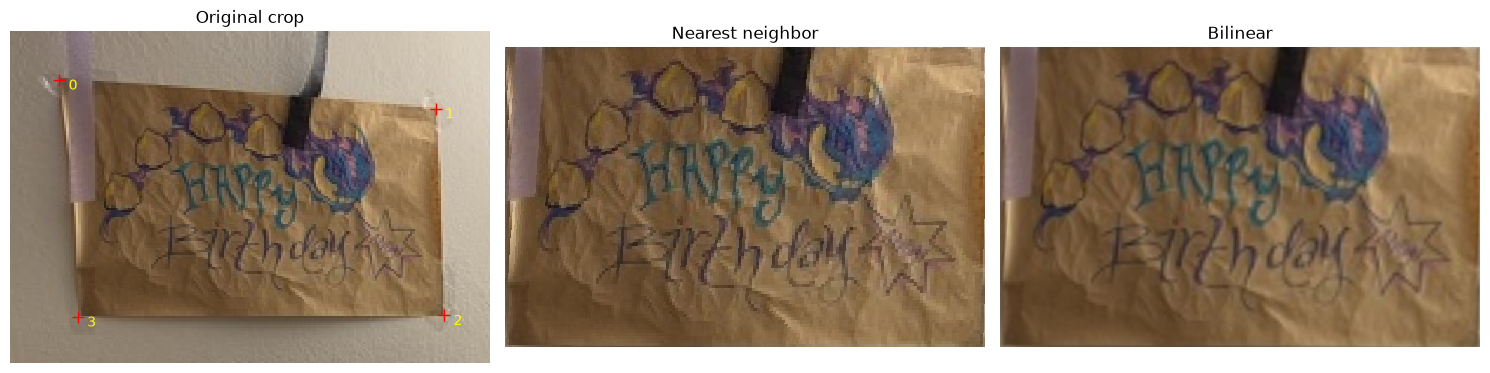

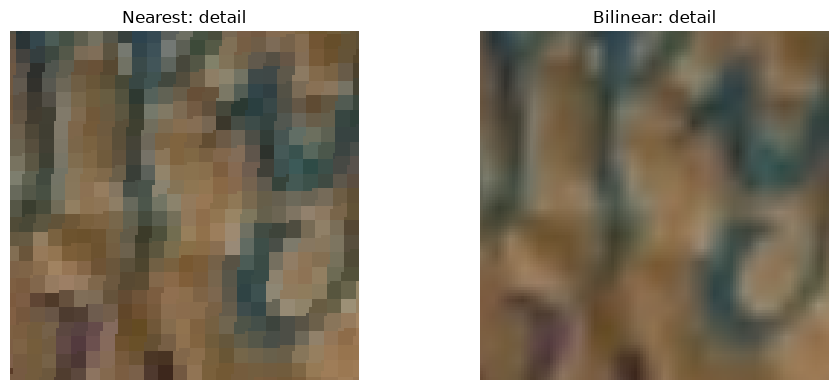

Botanical print H =
 [[ 6.69915766e+00 -5.49083674e-11 -3.08636893e+03]
 [ 2.10115990e-01  6.39058660e+00 -1.27906106e+03]
 [ 4.93995010e-04 -3.68617504e-04  1.00000000e+00]]
Nearest: 0.014s | Bilinear: 0.047s


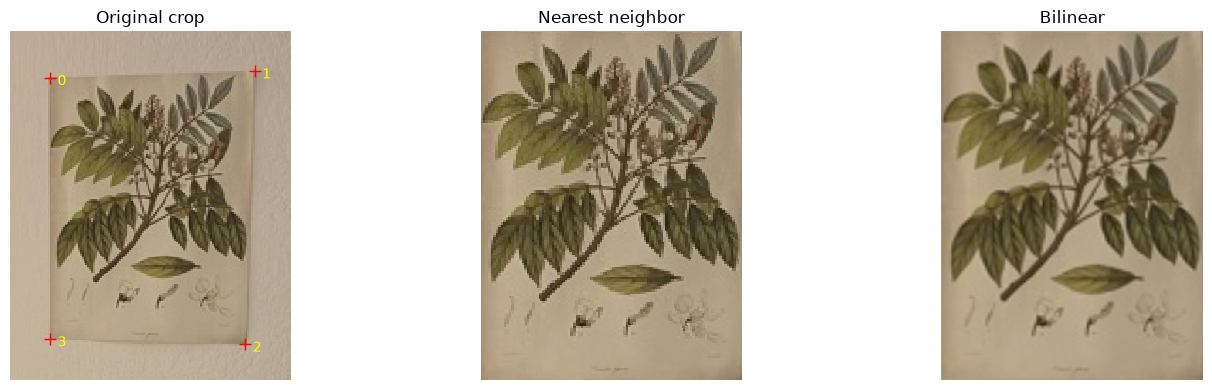

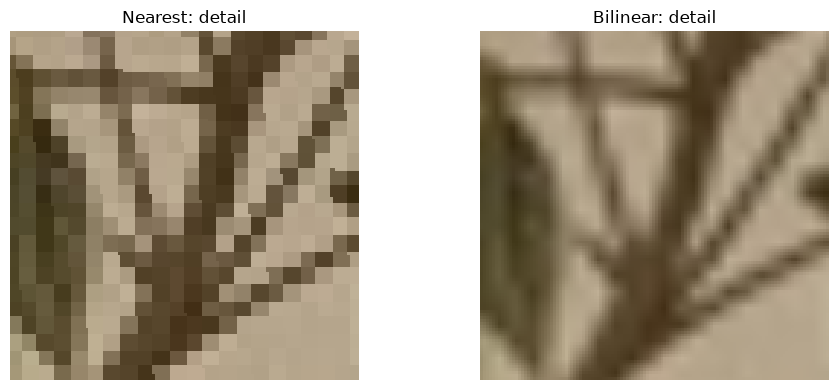

In [ ]:
timings = []
for job in RECTIFICATIONS:
    image = load_image(ASSETS / job["image"])
    corners = np.asarray(job["corners"])
    width, height = job["size"]
    target = [[0, 0], [width-1, 0], [width-1, height-1], [0, height-1]]
    H = computeH(corners, target)
    bounds = (0, 0, width-1, height-1)

    start = perf_counter()
    nearest = warpImageNearestNeighbor(image, H, bounds)
    nearest_time = perf_counter() - start
    start = perf_counter()
    bilinear = warpImageBilinear(image, H, bounds)
    bilinear_time = perf_counter() - start
    timings.append([nearest_time, bilinear_time])

    slug = job["slug"]
    print(job["name"], "H =\n", H)
    print(f"Nearest: {nearest_time:.3f}s | Bilinear: {bilinear_time:.3f}s")
    plt.imsave(OUTPUTS / f"{slug}_nearest.png", np.clip(nearest, 0, 1))
    plt.imsave(OUTPUTS / f"{slug}_bilinear.png", np.clip(bilinear, 0, 1))
    np.savetxt(OUTPUTS / f"{slug}_H.txt", H)

    x0, y0 = corners.min(axis=0).astype(int) - 20
    x1, y1 = corners.max(axis=0).astype(int) + 20
    show_images([image[y0:y1, x0:x1], nearest, bilinear],
                ["Original crop", "Nearest neighbor", "Bilinear"],
                [corners - [x0, y0], [], []], save_as=f"{slug}_comparison.png")

    cy, cx = height // 2, width // 2
    crop = (slice(cy-60, cy+60), slice(cx-60, cx+60))
    show_images([nearest[crop], bilinear[crop]], ["Nearest: detail", "Bilinear: detail"],
                save_as=f"{slug}_detail.png")

np.savetxt(OUTPUTS / "timings.csv", timings, delimiter=",",
           header="nearest_seconds,bilinear_seconds", comments="")

## A.4: Mosaics

In [6]:
def build_mosaic(images, homographies):
    bounds = canvas_bounds(images, homographies)
    xmin, ymin, xmax, ymax = bounds
    color_sum = np.zeros((ymax-ymin+1, xmax-xmin+1, 3), dtype=np.float32)
    weight_sum = np.zeros(color_sum.shape[:2], dtype=np.float32)

    for im, H in zip(images, homographies):
        height, width = im.shape[:2]
        y, x = np.indices((height, width))
        weight = np.minimum.reduce([x+1, y+1, width-x, height-y]).astype(np.float32)
        weight /= weight.max()
        warped, _ = warp_image(im, H, bounds=bounds)
        weight, _ = warp_image(weight, H, bounds=bounds)
        color_sum += warped * weight[..., None]
        weight_sum += weight

    return color_sum / np.maximum(weight_sum[..., None], 1e-8)


In [7]:
MOSAICS = [{'name': 'Gateway Building',
  'folder': 'gateway',
  'images': ['left.jpeg', 'right.jpeg'],
  'reference': 1,
  'matches': [{'source': 0,
               'im1_pts': [[656.68, 481.92], [565.31, 708.12], [556.88, 570.87], [712.27, 595.62],
                           [564.63, 478.48], [643.05, 659.83], [637.01, 565.1], [562.7, 649.68],
                           [706.86, 502.41], [696.94, 545.73], [625.97, 458.09], [648.62, 519.6],
                           [594.84, 569.11], [542.55, 538.6], [665.66, 575.7], [591.26, 492.53]],
               'im2_pts': [[126.85, 457.14], [32.75, 697.14], [20.81, 551.95], [179.37, 565.14],
                           [29.13, 451.91], [113.64, 634.46], [106.73, 540.83], [28.59, 635.66],
                           [173.75, 477.29], [164.32, 519.36], [95.58, 432.0], [119.96, 494.58],
                           [64.42, 547.46], [6.1, 517.54], [135.34, 548.83], [59.24, 467.23]]}]},
 {'name': 'Undergrad Academic Building',
  'folder': 'undergrad',
  'images': ['left.jpeg', 'center.jpeg', 'right.jpeg'],
  'reference': 1,
  'matches': [{'source': 0,
               'im1_pts': [[694.56, 522.08], [571.8, 97.0], [295.07, 463.48], [475.81, 610.95],
                           [551.59, 369.55], [702.62, 224.72], [754.92, 382.47], [411.77, 320.01],
                           [421.77, 492.48], [572.35, 217.51], [591.24, 581.81], [332.47, 561.39],
                           [609.84, 455.85], [701.17, 612.95], [456.03, 398.48], [652.6, 381.79]],
               'im2_pts': [[416.24, 526.2], [314.16, 110.87], [3.1, 452.76], [209.84, 614.61],
                           [291.68, 375.01], [427.8, 255.65], [468.15, 403.38], [146.75, 306.55],
                           [154.61, 490.36], [311.94, 228.69], [323.93, 581.87], [46.91, 564.03],
                           [344.86, 462.48], [419.59, 608.57], [194.15, 394.06],
                           [383.59, 395.86]]},
              {'source': 2,
               'im1_pts': [[456.62, 265.79], [14.14, 190.92], [213.51, 607.71], [276.46, 51.05],
                           [230.44, 289.15], [337.22, 474.03], [129.02, 462.44], [425.68, 105.48],
                           [149.22, 172.1], [281.13, 170.14], [319.82, 581.41], [286.03, 388.66],
                           [183.74, 62.09], [127.0, 555.76], [445.1, 185.37], [80.47, 234.45]],
               'im2_pts': [[741.61, 247.21], [303.52, 238.44], [483.83, 616.27], [537.49, 59.63],
                           [497.06, 303.41], [608.9, 480.81], [403.57, 478.46], [700.88, 81.17],
                           [418.31, 201.7], [545.51, 177.5], [592.06, 593.65], [553.76, 395.69],
                           [447.98, 90.87], [403.87, 564.58], [726.09, 161.51],
                           [359.38, 270.06]]}]},
 {'name': 'My living room',
  'folder': 'living_room',
  'images': ['left.jpg', 'right.jpg'],
  'reference': 1,
  'matches': [{'source': 0,
               'im1_pts': [[645.84, 483.71], [781.59, 179.95], [624.84, 298.98], [716.69, 256.94],
                           [700.58, 357.58], [616.07, 389.48], [601.81, 537.03], [650.33, 244.84],
                           [675.22, 527.79], [682.6, 296.13], [652.46, 358.99], [652.64, 439.15],
                           [608.1, 349.07], [607.22, 427.11], [720.66, 300.96], [622.54, 458.39]],
               'im2_pts': [[106.79, 499.15], [223.07, 173.39], [65.26, 293.57], [164.04, 248.9],
                           [156.64, 355.5], [62.36, 397.67], [59.46, 569.01], [89.98, 233.54],
                           [142.86, 541.56], [132.08, 290.1], [102.84, 360.25], [110.36, 449.16],
                           [49.66, 351.74], [55.71, 442.47], [172.71, 294.9], [77.17, 475.69]]}]}]


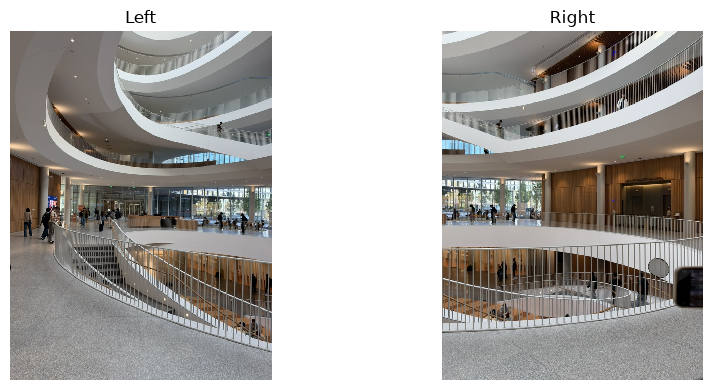

Gateway Building: left -> right
[[ 2.19328472e+00  1.43891127e-02 -1.18846321e+03]
 [ 7.32365932e-01  2.05001715e+00 -5.34406786e+02]
 [ 1.56646056e-03  3.45665302e-05  1.00000000e+00]]


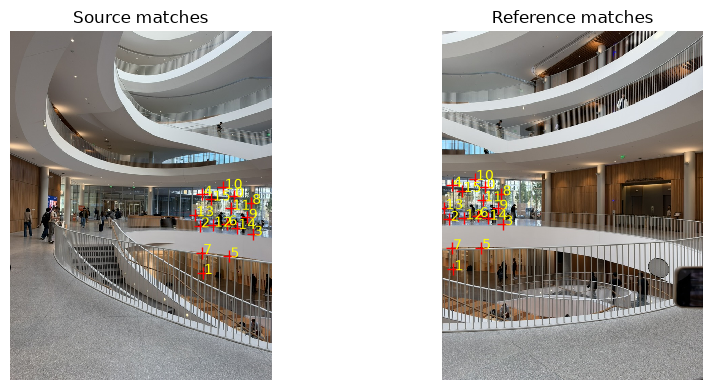

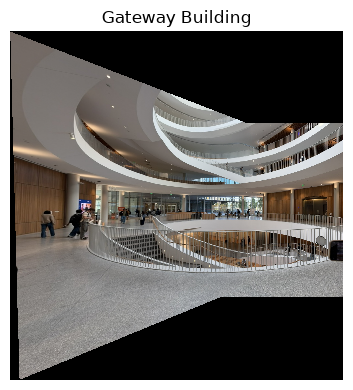

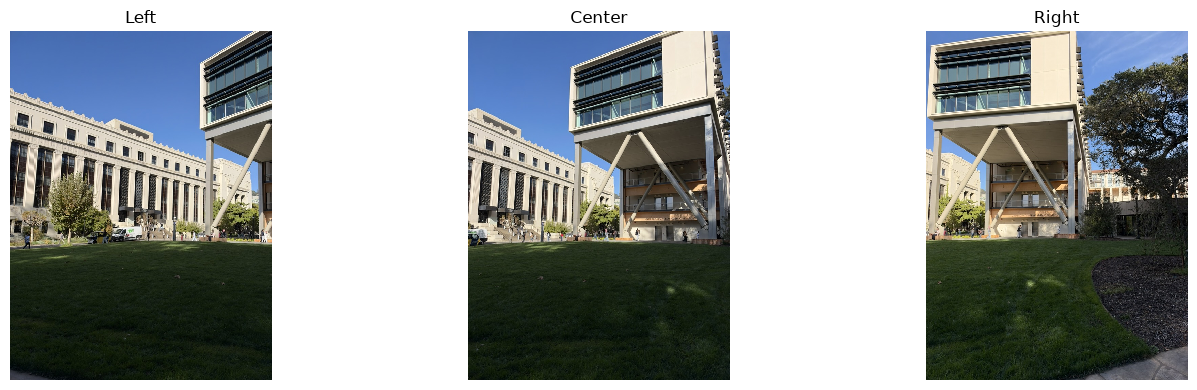

Undergrad Academic Building: left -> center
[[ 1.58900349e+00 -2.43877262e-02 -4.54429861e+02]
 [ 4.21084034e-01  1.39678146e+00 -2.16972301e+02]
 [ 7.59461876e-04  2.57790090e-06  1.00000000e+00]]


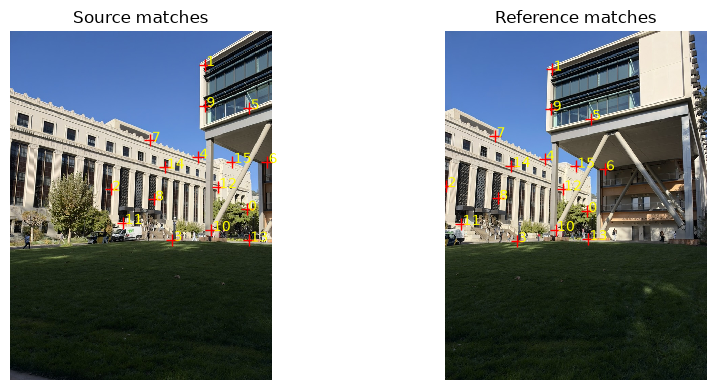

Undergrad Academic Building: right -> center
[[ 6.69601960e-01  5.62891437e-03  2.90372224e+02]
 [-2.32500982e-01  8.77424124e-01  7.23759560e+01]
 [-4.15657567e-04 -1.63142002e-05  1.00000000e+00]]


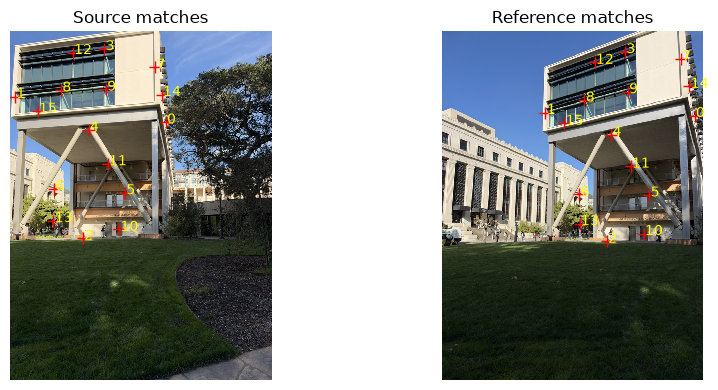

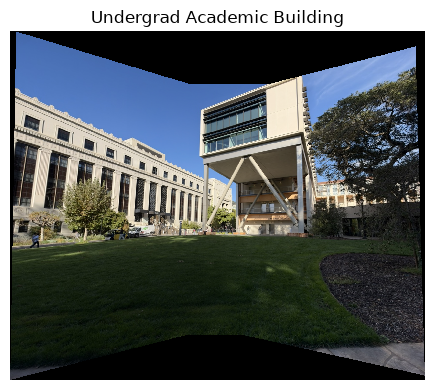

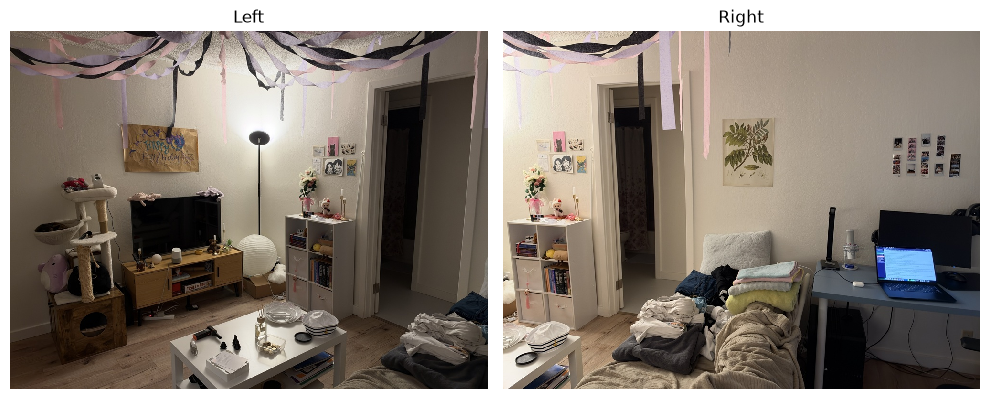

My living room: left -> right
[[ 2.82958986e+00  2.08827370e-01 -1.68508850e+03]
 [ 5.48513468e-01  2.55321383e+00 -4.50091958e+02]
 [ 1.94706976e-03  4.90011662e-05  1.00000000e+00]]


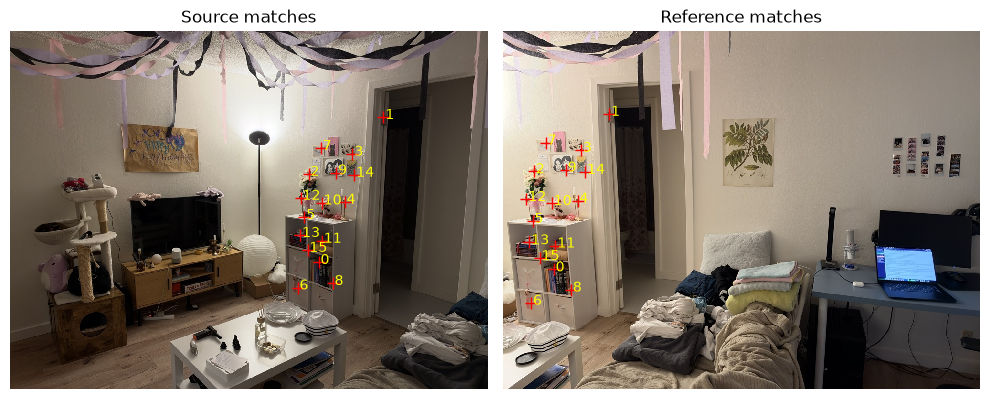

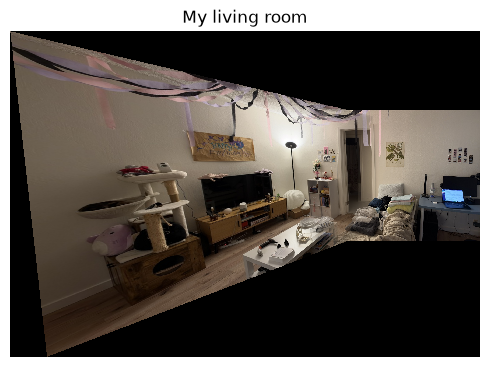

In [8]:
for job in MOSAICS:
    slug = job["folder"]
    paths = [ASSETS / slug / filename for filename in job["images"]]
    images = [load_image(path) for path in paths]
    reference = job["reference"]
    homographies = [np.eye(3) for _ in images]
    show_images(images, [path.stem.title() for path in paths], save_as=f"{slug}_sources.png")

    for match in job["matches"]:
        source = match["source"]
        H = computeH(match["im1_pts"], match["im2_pts"])
        homographies[source] = H
        side = paths[source].stem
        print(f"{job['name']}: {side} -> {paths[reference].stem}\n{H}")
        np.savetxt(OUTPUTS / f"{slug}_{side}_H.txt", H)
        show_images([images[source], images[reference]], ["Source matches", "Reference matches"],
                    [match["im1_pts"], match["im2_pts"]], save_as=f"{slug}_matches_{side}.png")

    mosaic = build_mosaic(images, homographies)
    plt.imsave(OUTPUTS / f"{slug}_mosaic.png", np.clip(mosaic, 0, 1))
    show_images([mosaic], [job["name"]])
